In [2]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.RadialExperiment import RadialDevice, SingleCellPlots, SingleSessionPlots, WidefieldAligner, SessionToWidefield
import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd

%load_ext autoreload
%autoreload 2

# # Session are
# # List of session info for import
session_info = [
    ('SAM041', '251126', 'tiling_5_120um'),
]

record_date = session_info[0][1]
mouse_name = session_info[0][0]
experiment_name = session_info[0][2]
session_data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
df_name = f'{record_date}_{mouse_name}_{experiment_name}_dataframe.pkl'
df_path = os.path.join(session_data_dir, df_name)

with open(df_path, 'rb') as f:
    session_df = pickle.load(f)
    print(f"File {df_name} imported.")

experiment_name = 'tiling_120um'
multi_session_dir = r'D:/data-distance-coding-project/multi-session-data/'
multi_session_dir = os.path.join(multi_session_dir, f'{mouse_name}_{experiment_name}')
alignment_name = f'{mouse_name}_{experiment_name}_alignment_parameters.pkl'
alignment_path = os.path.join(multi_session_dir, alignment_name)

with open(alignment_path, 'rb') as f:
    alignment_params = pickle.load(f)
    print(f"Alignment parameters loaded from {alignment_name}")

# session_dfs = []
# for mouse_name, record_date, experiment_name in session_infos:
#     this_data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
#     df_name = f'{record_date}_{mouse_name}_{experiment_name}_dataframe.pkl'
#     df_path = os.path.join(this_data_dir, df_name)
#     try:
#         with open(df_path, 'rb') as f:
#             this_session_df = pickle.load(f)
#             print(f"File {df_name} imported.")
#     except FileNotFoundError:
#         print(f"The file {df_name} does not exist.")
       
#         R = RadialDevice(mouse_name=mouse_name, record_date=record_date, experiment_name=experiment_name)
#         this_session_df = R.analyze_session_stats()
#         with open(df_path, 'wb') as f:
#             pickle.dump(this_session_df, f)
#         this_session_df = None
#     session_dfs.append(this_session_df)

File 251126_SAM041_tiling_5_120um_dataframe.pkl imported.
Alignment parameters loaded from SAM041_tiling_120um_alignment_parameters.pkl


In [4]:
WF_Aligner = WidefieldAligner('SAM041', 'tiling_120um')

Starting sequential alignment to widefield...
Sessions to align: [['SAM041', '251126', 'tiling_1_120um'], ['SAM041', '251126', 'tiling_2_120um'], ['SAM041', '251128', 'tiling_3_120um'], ['SAM041', '251128', 'tiling_4_120um'], ['SAM041', '251126', 'tiling_5_120um'], ['SAM041', '251126', 'tiling_6_120um'], ['SAM041', '251128', 'tiling_7_120um'], ['SAM041', '251128', 'tiling_8_120um'], ['SAM041', '251126', 'tiling_9_120um']]

Aligning session ['SAM041', '251126', 'tiling_1_120um']...


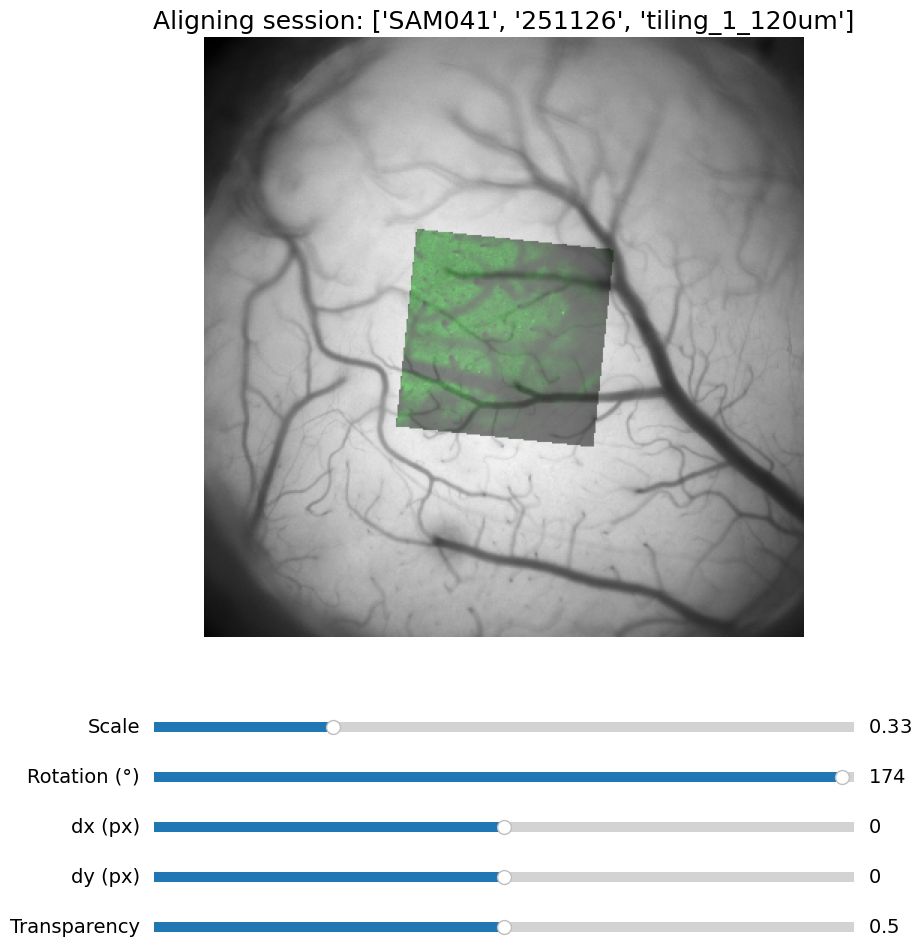

TypeError: unhashable type: 'list'

In [5]:
alignment_params = WF_Aligner.align_all_sessions_to_widefield()

In [195]:
SAM041_wf = SessionToWidefield(session_info)

Alignment parameters loaded from SAM041_tiling_120um_alignment_parameters.pkl
Session dataframe loaded from 251126_SAM041_tiling_5_120um_dataframe.pkl


In [190]:
SAM041_wf.alignment_params.keys()

dict_keys(['widefield_maps', 'areas_verts', 'session_names', 'field_coordinates_widefield'])

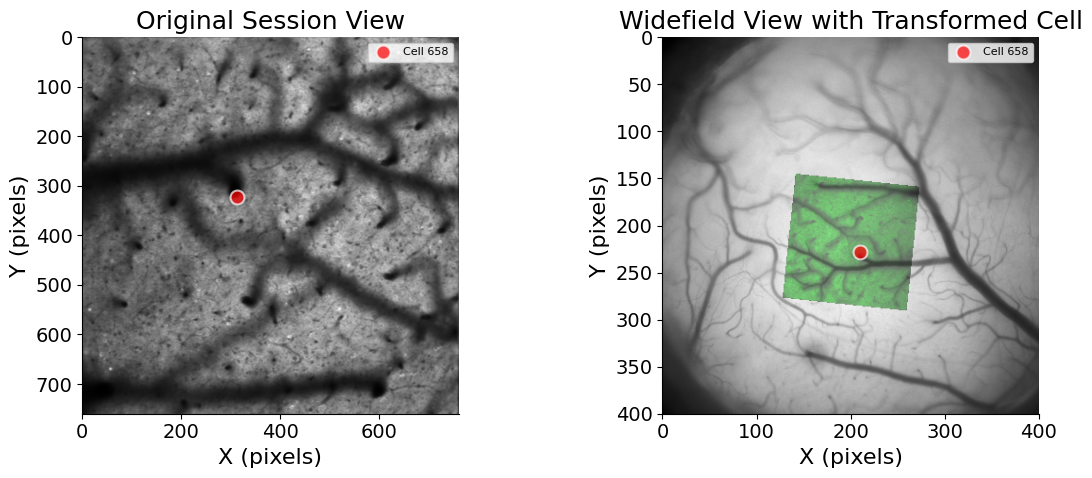

(<Figure size 1200x500 with 2 Axes>,
 (<Axes: title={'center': 'Original Session View'}, xlabel='X (pixels)', ylabel='Y (pixels)'>,
  <Axes: title={'center': 'Widefield View with Transformed Cell'}, xlabel='X (pixels)', ylabel='Y (pixels)'>))

In [198]:
SAM041_wf.plot_cell_in_widefield(cell_id=658)

In [201]:
session_df = SAM041_wf.append_widefield_to_session_df()

Added widefield coordinates and retinotopy values for 2426 cells


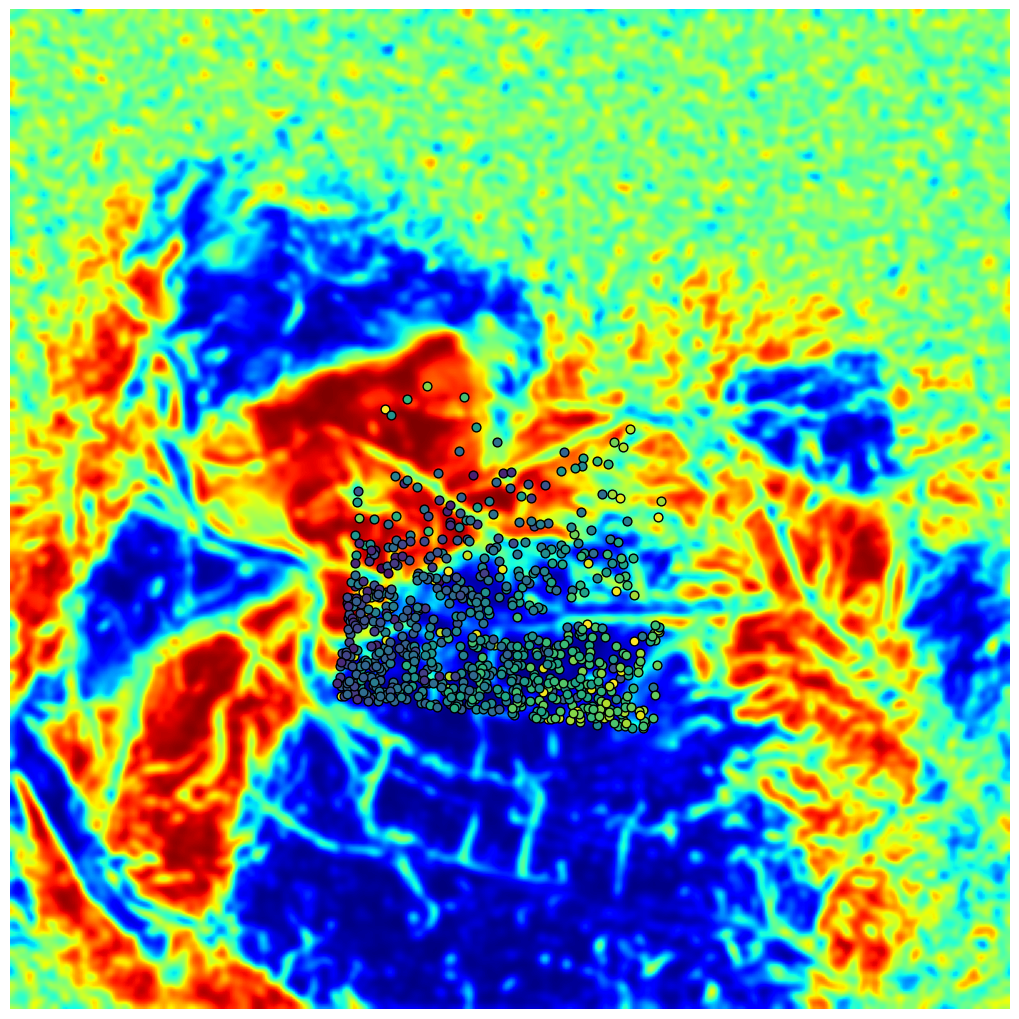

In [242]:
# Plot cells on widefield map using coordinates from session_df
fig, ax = plt.subplots(figsize=(10, 10))

# Load widefield map
widefield_map = SAM041_wf.alignment_params['widefield_maps']['VFS']  # Assuming first map is the reference

# Display widefield map
ax.imshow(widefield_map, cmap='jet', origin='upper')

# Get reliable cells from session_df
reliable = session_df[
            (session_df['monocular'].apply(lambda x: x['reliable']) == True) &
            (session_df['binocular'].apply(lambda x: x['reliable']) == True) &
            ((session_df['monocular'].apply(lambda x: x['reliable_corr']) >= 0.8) |
            (session_df['binocular'].apply(lambda x: x['reliable_corr']) >= 0.8))
        ]['cell_id'].values

# Scatter plot each cell using widefield coordinates
for idx, row in session_df.iterrows():
    cell_id = row['cell_id']
    wf_x = row['wf_coords'][0]
    wf_y = row['wf_coords'][1]
    
    if not cell_id in reliable:
        # sc = ax.scatter(
        #     wf_x, wf_y,
        #     c='lightgray',
        #     s=40, alpha=0.5,
        #     edgecolor='black', linewidth=1
        # )
        continue
    else:
        rf_location = row['RF']
        sc = ax.scatter(
            wf_x, wf_y,
            c=rf_location,
            cmap='viridis',
            vmin=-30,
            vmax=60,
            s=40, alpha=1,
            edgecolor='black', linewidth=1
        )

# Remove axes for clean visualization
ax.axis('off')
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.margins(0, 0)
plt.tight_layout(pad=0)

plt.show()

In [215]:
print(np.min(session_df['azi']), np.max(session_df['azi']))
print(np.min(session_df['alt']), np.max(session_df['alt']))

-24.51610404355517 6.4734058461338755
-16.383482641900827 1.848979745504775


In [220]:
print(np.min(SAM041_wf.alignment_params['widefield_maps']['azi']), np.max(SAM041_wf.alignment_params['widefield_maps']['azi']))
print(np.min(SAM041_wf.alignment_params['widefield_maps']['alt']), np.max(SAM041_wf.alignment_params['widefield_maps']['alt']))

-26.028052697334783 44.883504174310104
-16.383482641900827 19.30965897499754


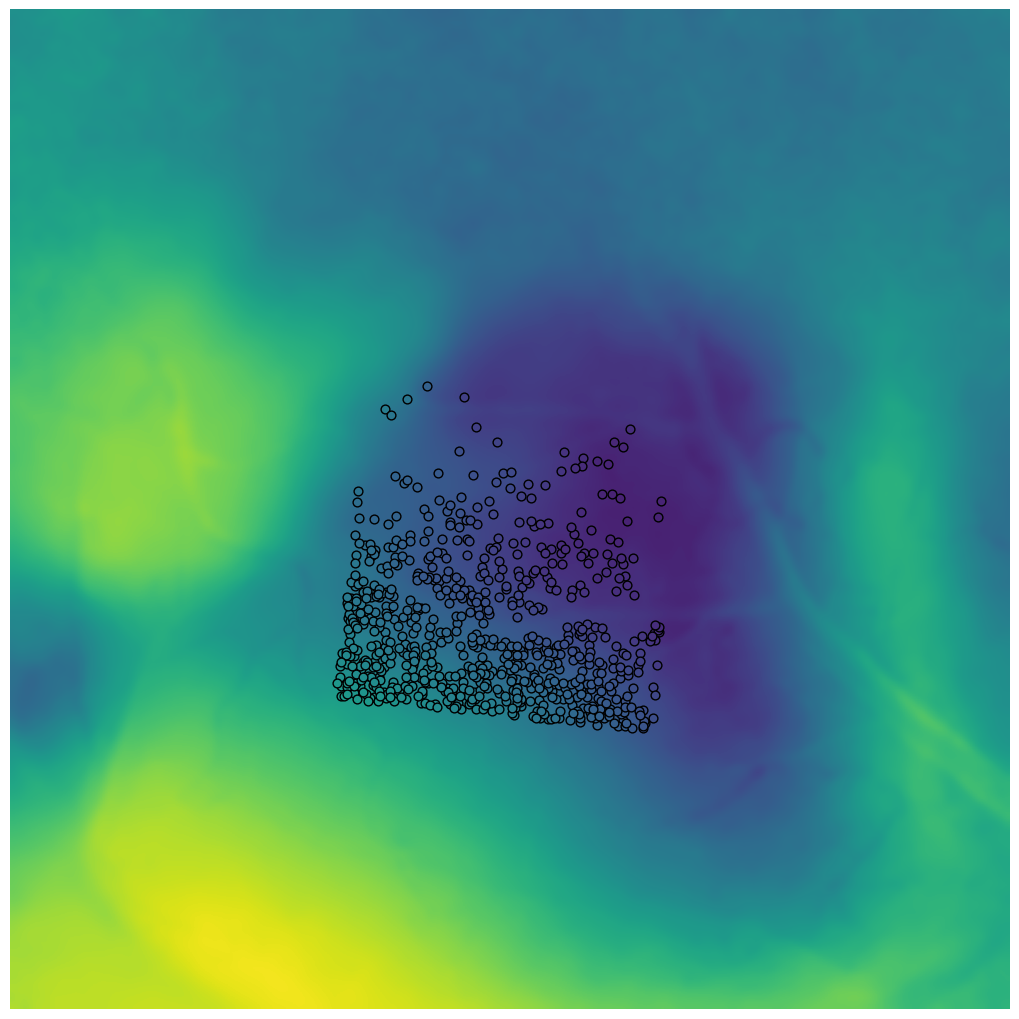

In [222]:
# Plot cells on widefield map using coordinates from session_df
fig, ax = plt.subplots(figsize=(10, 10))

# Load widefield map
widefield_map = SAM041_wf.alignment_params['widefield_maps']['alt']  # Assuming first map is the reference

# Display widefield map
ax.imshow(widefield_map, cmap='viridis', vmin=-20, vmax=20, origin='upper')

# Get reliable cells from session_df
reliable = session_df[
            (session_df['monocular'].apply(lambda x: x['reliable']) == True) &
            (session_df['binocular'].apply(lambda x: x['reliable']) == True) &
            ((session_df['monocular'].apply(lambda x: x['reliable_corr']) >= 0.8) |
            (session_df['binocular'].apply(lambda x: x['reliable_corr']) >= 0.8))
        ]['cell_id'].values

# Scatter plot each cell using widefield coordinates
for idx, row in session_df.iterrows():
    cell_id = row['cell_id']
    wf_x = row['wf_coords'][0]
    wf_y = row['wf_coords'][1]
    
    if not cell_id in reliable:
        # sc = ax.scatter(
        #     wf_x, wf_y,
        #     c='lightgray',
        #     s=40, alpha=0.5,
        #     edgecolor='black', linewidth=1
        # )
        continue
    else:
        alt = row['alt']
        sc = ax.scatter(
            wf_x, wf_y,
            c=alt,
            cmap='viridis',
            vmin=-20,
            vmax=20,
            s=40, alpha=1,
            edgecolor='black', linewidth=1
        )

# Remove axes for clean visualization
ax.axis('off')
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.margins(0, 0)
plt.tight_layout(pad=0)

plt.show()

In [223]:
# Get reliable cells from session_df
reliable = session_df[
            (session_df['monocular'].apply(lambda x: x['reliable']) == True) &
            (session_df['binocular'].apply(lambda x: x['reliable']) == True) &
            ((session_df['monocular'].apply(lambda x: x['reliable_corr']) >= 0.8) |
            (session_df['binocular'].apply(lambda x: x['reliable_corr']) >= 0.8))
        ]['cell_id'].values

not_reliable = np.setdiff1d(session_df['cell_id'].values, reliable)

# Filter for cells that are in the reliable set AND meet the monocular/binocular criteria
monocular_only = session_df[
    (session_df['cell_id'].isin(reliable)) &
    (session_df['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
    (session_df['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
]['cell_id'].values

binocular_only = session_df[
    (session_df['cell_id'].isin(reliable)) &
    (session_df['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
    (session_df['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
]['cell_id'].values

both = session_df[
    (session_df['cell_id'].isin(reliable)) &
    (session_df['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
    (session_df['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
]['cell_id'].values

none = session_df[
    (session_df['cell_id'].isin(reliable)) &
    (session_df['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
    (session_df['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
]['cell_id'].values

reliable_classes = {
    'reliable': reliable,
    'not_reliable': not_reliable,
}

modulated_classes = {
    'binocular': binocular_only,
    'monocular': monocular_only,
    'both': both,
    'none': none
}

total_cells = len(session_df)
print(f"Reliable cells: {len(reliable)} ({len(reliable)/total_cells*100:.1f}%)")
print(f"Not reliable cells: {len(not_reliable)} ({len(not_reliable)/total_cells*100:.1f}%)")
print(f"Monocular cells: {len(monocular_only)} ({len(monocular_only)/len(reliable)*100:.1f}%)")
print(f"Binocular cells: {len(binocular_only)} ({len(binocular_only)/len(reliable)*100:.1f}%)")
print(f"Both cells: {len(both)} ({len(both)/len(reliable)*100:.1f}%)")
print(f"None cells: {len(none)} ({len(none)/len(reliable)*100:.1f}%)")

Reliable cells: 702 (28.9%)
Not reliable cells: 1724 (71.1%)
Monocular cells: 36 (5.1%)
Binocular cells: 86 (12.3%)
Both cells: 6 (0.9%)
None cells: 574 (81.8%)


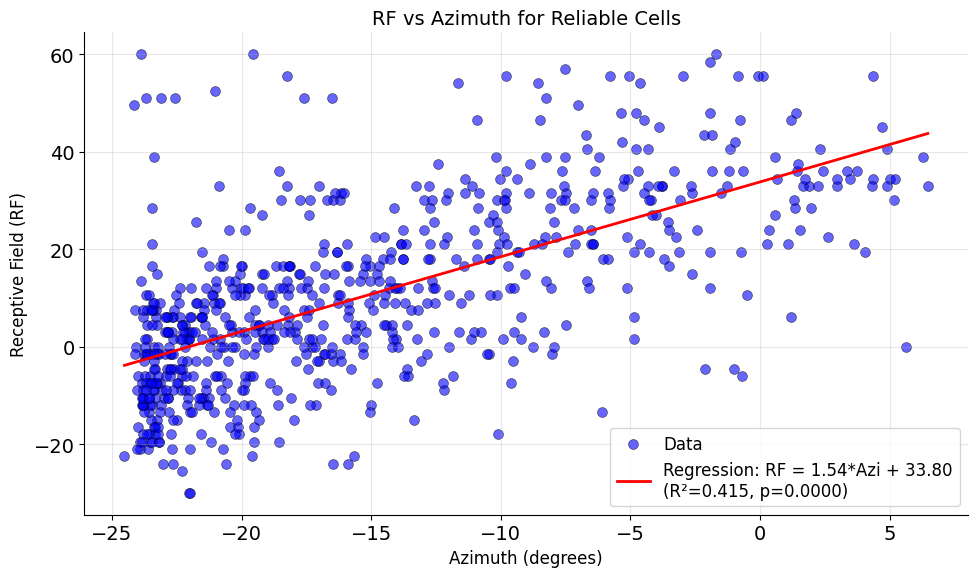

Plotted 702 reliable cells
Regression: RF ≈ 1.54 * Azimuth + 33.80
R² = 0.4153, p-value = 0.0000


In [231]:
# Plot relationship between cell's RF and its azimuth location with regression

# Get reliable cells
reliable_cells = reliable_classes['reliable']

# Extract RF and azimuth values for reliable cells
rf_values = []
azi_values = []

for cell_id in reliable_cells:
    cell_row = session_df[session_df['cell_id'] == cell_id]
    if len(cell_row) > 0 and 'azi' in cell_row.columns:
        # Get RF value (using binocular condition as default)
        rf = cell_row['binocular'].values[0].get('RF', None)
        azi = cell_row['azi'].values[0]
        
        if rf is not None and azi is not None and not np.isnan(rf) and not np.isnan(azi):
            rf_values.append(rf)
            azi_values.append(azi)

# Convert to numpy arrays for regression
rf_values = np.array(rf_values)
azi_values = np.array(azi_values)

# Perform linear regression
from scipy import stats
slope, intercept, r_value, p_value, std_err = stats.linregress(azi_values, rf_values)

# Create regression line
azi_line = np.linspace(azi_values.min(), azi_values.max(), 100)
rf_line = slope * azi_line + intercept

# Create scatter plot with regression line
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(azi_values, rf_values, alpha=0.6, s=50, c='blue', edgecolors='black', linewidth=0.5, label='Data')
ax.plot(azi_line, rf_line, 'r-', linewidth=2, label=f'Regression: RF = {slope:.2f}*Azi + {intercept:.2f}\n(R²={r_value**2:.3f}, p={p_value:.4f})')
ax.set_xlabel('Azimuth (degrees)', fontsize=12)
ax.set_ylabel('Receptive Field (RF)', fontsize=12)
ax.set_title('RF vs Azimuth for Reliable Cells', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Plotted {len(rf_values)} reliable cells")
print(f"Regression: RF ≈ {slope:.2f} * Azimuth + {intercept:.2f}")
print(f"R² = {r_value**2:.4f}, p-value = {p_value:.4f}")

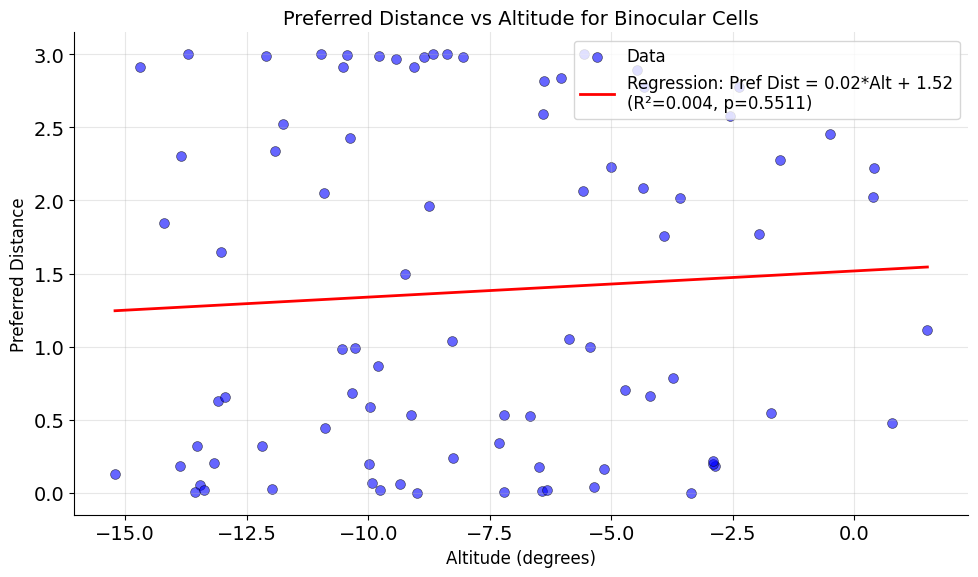

Plotted 86 binocular cells
Regression: Pref Distance ≈ 0.02 * Altitude + 1.52
R² = 0.0042, p-value = 0.5511


In [238]:
# Get reliable cells
binocular_only = modulated_classes['binocular']

# Extract preferred distance and altitude values for binocular cells
pref_distance_values = []
alt_values = []

for cell_id in binocular_only:
    cell_row = session_df[session_df['cell_id'] == cell_id]
    if len(cell_row) > 0 and 'alt' in cell_row.columns:
        # Get preferred distance value (using binocular condition as default)
        pref_distance = cell_row['binocular'].values[0].get('distance', None)
        alt = cell_row['alt'].values[0]
        
        if pref_distance is not None and alt is not None and not np.isnan(pref_distance) and not np.isnan(alt):
            pref_distance_values.append(pref_distance)
            alt_values.append(alt)

# Convert to numpy arrays
pref_distance_values = np.array(pref_distance_values)
alt_values = np.array(alt_values)

# Only perform regression if we have data
if len(pref_distance_values) > 0 and len(alt_values) > 0:
    # Perform linear regression
    from scipy import stats
    slope, intercept, r_value, p_value, std_err = stats.linregress(alt_values, pref_distance_values)

    # Create regression line
    alt_line = np.linspace(alt_values.min(), alt_values.max(), 100)
    pref_distance_line = slope * alt_line + intercept

    # Create scatter plot with regression line
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(alt_values, pref_distance_values, alpha=0.6, s=50, c='blue', edgecolors='black', linewidth=0.5, label='Data')
    ax.plot(alt_line, pref_distance_line, 'r-', linewidth=2, label=f'Regression: Pref Dist = {slope:.2f}*Alt + {intercept:.2f}\n(R²={r_value**2:.3f}, p={p_value:.4f})')
    ax.set_xlabel('Altitude (degrees)', fontsize=12)
    ax.set_ylabel('Preferred Distance', fontsize=12)
    ax.set_title('Preferred Distance vs Altitude for Binocular Cells', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"Plotted {len(pref_distance_values)} binocular cells")
    print(f"Regression: Pref Distance ≈ {slope:.2f} * Altitude + {intercept:.2f}")
    print(f"R² = {r_value**2:.4f}, p-value = {p_value:.4f}")
else:
    print(f"No valid data found for binocular cells (found {len(binocular_only)} binocular cells)")


In [157]:
# Find the index of the current session in the alignment parameters
session_names = alignment_params['session_names']
session_index = next((i for i, name in enumerate(session_names) if name == list(session_info[0])), None)
print(f"Session index: {session_index}")

session_alignment = alignment_params['field_coordinates_widefield'][session_index]
print(session_alignment)

Session index: 4
{'scale': 0.33, 'rotation': 174, 'dx': 0, 'dy': 17}


-66.8048780487805 56.804878048780495


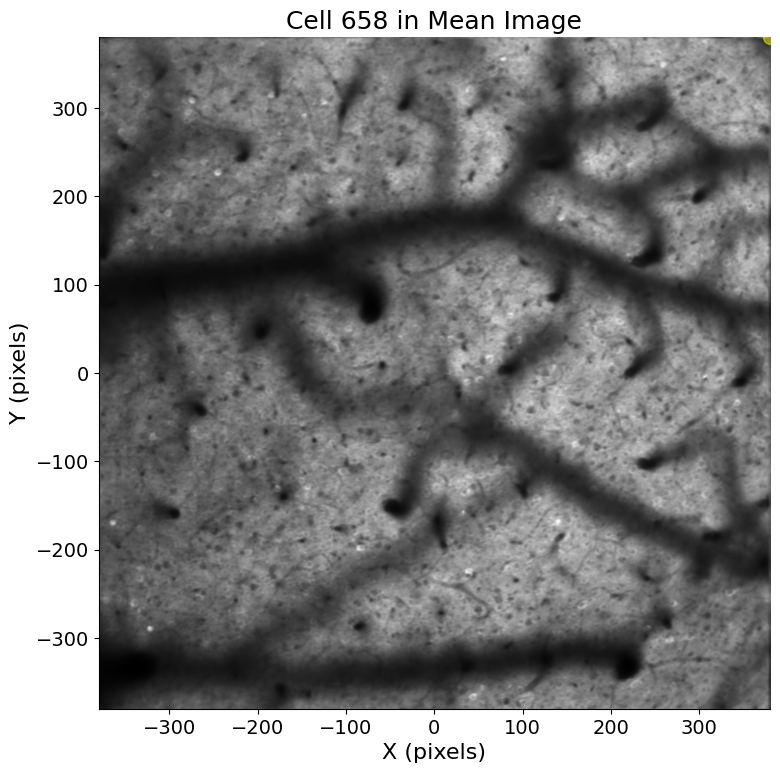

In [159]:
cell_id = 658
cell_stat = suite2p_stat[cell_id]

# Draw cell in its mean image
fig, ax = plt.subplots(figsize=(8, 8))

# Load mean image from suite2p ops
ops_path = os.path.join(session_data_dir, 'suite2p', 'plane0', 'ops.npy')
ops = np.load(ops_path, allow_pickle=True).item()
mean_img = ops['meanImg']

# Display mean image
ax.imshow(mean_img, cmap='gray', extent=[-380, 380, -380, 380], origin='upper')

# Get cell pixels and plot them
cell_xpix = cell_stat['xpix'][~cell_stat['overlap']].mean() - 380
cell_ypix = -cell_stat['ypix'][~cell_stat['overlap']].mean() + 380

print(cell_xpix, cell_ypix)

ax.scatter(380,380, c='yellow', s=100, alpha=0.5)

ax.set_title(f'Cell {cell_id} in Mean Image')
ax.set_xlabel('X (pixels)')
ax.set_ylabel('Y (pixels)')
plt.tight_layout()
plt.show()

0.33 174 0 17
Original cell position:
380 380


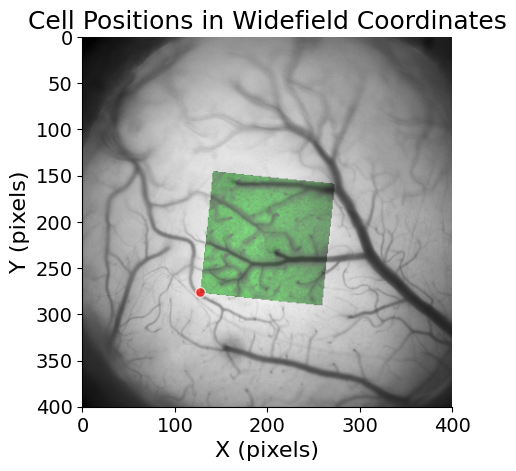

In [ ]:
import cv2

scale = session_alignment['scale']
rotation = session_alignment['rotation']
dx = session_alignment['dx']
dy = session_alignment['dy']

print(scale, rotation, dx, dy)

cell_xpix = 380
cell_ypix = 380

print('Original cell position:')
print(cell_xpix, cell_ypix)


cell_id = 658
cell_stat = suite2p_stat[cell_id]

# Draw cell in its mean image
fig, ax = plt.subplots(figsize=(8, 8))

# Load mean image from suite2p ops
ops_path = os.path.join(session_data_dir, 'suite2p', 'plane0', 'ops.npy')
ops = np.load(ops_path, allow_pickle=True).item()
mean_img = ops['meanImg']

# Display mean image
ax.imshow(mean_img, cmap='gray', extent=[-380, 380, -380, 380], origin='upper')

# Get cell pixels and plot them
cell_xpix = cell_stat['xpix'][~cell_stat['overlap']].mean() - 380
cell_ypix = -cell_stat['ypix'][~cell_stat['overlap']].mean() + 380

print(cell_xpix, cell_ypix)

ax.scatter(380,380, c='yellow', s=100, alpha=0.5)

ax.set_title(f'Cell {cell_id} in Mean Image')
ax.set_xlabel('X (pixels)')
ax.set_ylabel('Y (pixels)')
plt.tight_layout()
plt.show()

def transform_cell_to_widefield(cell_xpix, cell_ypix):
    """
    Transform a cell's coordinates from 2P image space to widefield space.
    Uses the same transformation matrix as cv2.warpAffine for consistency.
    
    Parameters
    ----------
    cell_xpix : float
        Cell x coordinate in 2P image space (0,0 = center)
    cell_ypix : float
        Cell y coordinate in 2P image space (0,0 = center)
        
    Returns
    -------
    x_final : float
        Cell x coordinate in widefield space (pixels)
    y_final : float
        Cell y coordinate in widefield space (pixels)
    """
    # Get alignment parameters
    scale = session_alignment['scale']
    rotation = session_alignment['rotation']
    dx = session_alignment['dx']
    dy = session_alignment['dy']
    
    h_orig, w_orig = 760, 760  # Original 2P image dimensions
    h_wf, w_wf = 400, 400  # Widefield image dimensions

    # Step 1: Convert from centered coordinates to pixel coordinates
    x_pixels = cell_xpix + 380
    y_pixels = 380 - cell_ypix  # Flip Y-axis!

    # Step 2: Resize coordinates from 760x760 to 400x400 space
    x_resized = x_pixels * (w_wf / w_orig)
    y_resized = y_pixels * (h_wf / h_orig)

    # Step 3: Apply the SAME transformation matrix that cv2 uses
    center = (w_wf / 2, h_wf / 2)
    
    # Create the rotation+scale matrix (same as cv2.getRotationMatrix2D)
    M_rot = cv2.getRotationMatrix2D(center, rotation, scale)
    M_rot[0, 2] += dx
    M_rot[1, 2] += dy
    
    # Apply the transformation matrix to the point
    # M * [x, y, 1]^T = [x', y']^T
    point = np.array([x_resized, y_resized, 1])
    transformed_point = M_rot @ point
    
    x_final, y_final = transformed_point[0], transformed_point[1]
    
    return x_final, y_final

# Apply the transformation
x_final, y_final = transform_cell_to_widefield(cell_xpix=380, cell_ypix=380)

# Plot x_final and y_final in the widefield image with session overlay
fig, ax = plt.subplots(figsize=(5, 5))

# Get widefield reference
widefield = alignment_params['widefield_maps']['img'].copy()
widefield_norm = (widefield - widefield.min()) / (widefield.max() - widefield.min())

# Create composite with widefield as grayscale
composite = np.stack([widefield_norm, widefield_norm, widefield_norm], axis=2)

# Get session mean image and transform it
mean_img = ops['meanImg']  # Assuming first session
mean_img_norm = (mean_img - mean_img.min()) / (mean_img.max() - mean_img.min())
mean_img_resized = cv2.resize(mean_img_norm, (widefield.shape[1], widefield.shape[0]), interpolation=cv2.INTER_LINEAR)

# Apply transformation
h, w = mean_img_resized.shape[:2]
center = (w / 2, h / 2)

M_rot = cv2.getRotationMatrix2D(center, rotation, scale)
M_rot[0, 2] += dx
M_rot[1, 2] += dy

transformed = cv2.warpAffine(
    mean_img_resized, M_rot, (w, h),
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

# Blend session in green
alpha = 0.5
session_green = np.zeros_like(composite)
session_green[:, :, 1] = transformed
mask = (transformed > 0).astype(float)
composite = composite * (1 - alpha * mask[:, :, None]) + session_green * alpha

# Display composite
ax.imshow(composite, extent=[0, 400, 400, 0], origin='upper')
ax.scatter(x_final, y_final, color='red', s=50, alpha=0.7, edgecolors='white', linewidths=1)
ax.set_title('Cell Positions in Widefield Coordinates')
ax.set_xlabel('X (pixels)')
ax.set_ylabel('Y (pixels)')
plt.tight_layout()
plt.show()

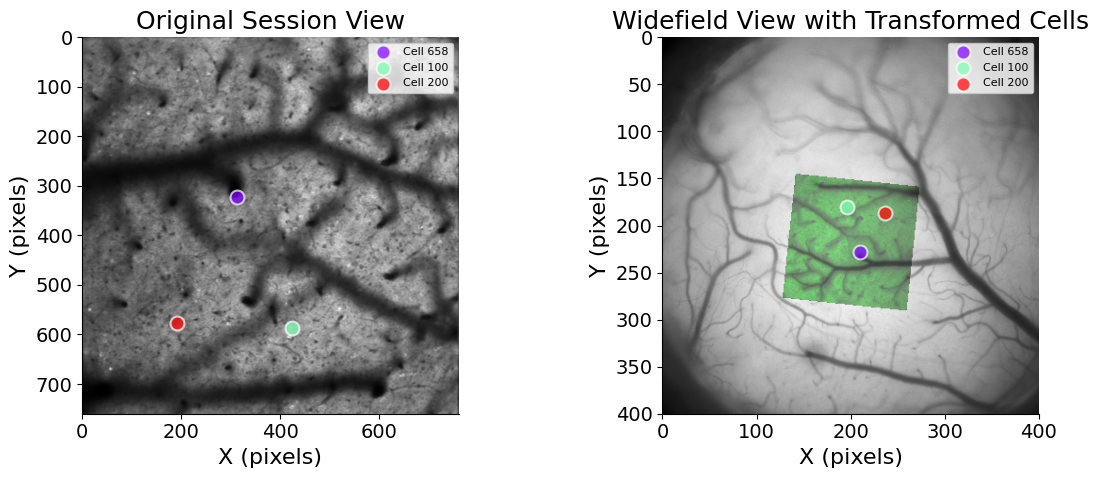

In [179]:
def plot_cells_in_widefield(cell_indices):
    """
    Plot cells in both their original session view and transformed to widefield.
    
    Parameters
    ----------
    cell_indices : list of int
        List of cell indices to plot
    """
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    
    # Generate colors for each cell
    colors = cm.rainbow(np.linspace(0, 1, len(cell_indices)))
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # LEFT PLOT: Original session
    mean_img = ops['meanImg']
    ax1.imshow(mean_img, cmap='gray', extent=[0, 760, 760, 0], origin='upper')
    
    # Plot each cell in original coordinates
    for idx, cell_id in enumerate(cell_indices):
        cell_stat = suite2p_stat[cell_id]
        # Get raw pixel coordinates (no transformation needed)
        xpix_raw = cell_stat['xpix'][~cell_stat['overlap']].mean()
        ypix_raw = cell_stat['ypix'][~cell_stat['overlap']].mean()
        
        ax1.scatter(xpix_raw, ypix_raw, c=[colors[idx]], s=100, 
                   alpha=0.7, edgecolors='white', linewidths=1.5,
                   label=f'Cell {cell_id}')
    
    ax1.set_title('Original Session View')
    ax1.set_xlabel('X (pixels)')
    ax1.set_ylabel('Y (pixels)')
    ax1.legend(loc='upper right', fontsize=8)
    
    # RIGHT PLOT: Widefield composite
    widefield = alignment_params['widefield_maps']['img'].copy()
    widefield_norm = (widefield - widefield.min()) / (widefield.max() - widefield.min())
    composite = np.stack([widefield_norm, widefield_norm, widefield_norm], axis=2)
    
    # Transform and overlay session
    mean_img_norm = (mean_img - mean_img.min()) / (mean_img.max() - mean_img.min())
    mean_img_resized = cv2.resize(mean_img_norm, (widefield.shape[1], widefield.shape[0]), 
                                   interpolation=cv2.INTER_LINEAR)
    
    h, w = mean_img_resized.shape[:2]
    center = (w / 2, h / 2)
    
    M_rot = cv2.getRotationMatrix2D(center, session_alignment['rotation'], 
                                     session_alignment['scale'])
    M_rot[0, 2] += session_alignment['dx']
    M_rot[1, 2] += session_alignment['dy']
    
    transformed = cv2.warpAffine(mean_img_resized, M_rot, (w, h),
                                  borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    
    # Blend session in green
    alpha = 0.5
    session_green = np.zeros_like(composite)
    session_green[:, :, 1] = transformed
    mask = (transformed > 0).astype(float)
    composite = composite * (1 - alpha * mask[:, :, None]) + session_green * alpha
    
    ax2.imshow(composite, extent=[0, 400, 400, 0], origin='upper')
    
    # Transform and plot each cell
    for idx, cell_id in enumerate(cell_indices):
        cell_stat = suite2p_stat[cell_id]
        xpix_raw = cell_stat['xpix'][~cell_stat['overlap']].mean()
        ypix_raw = cell_stat['ypix'][~cell_stat['overlap']].mean()
        
        # Convert to centered coordinates
        cell_xpix_centered = xpix_raw - 380
        cell_ypix_centered = -ypix_raw + 380
        
        # Transform to widefield
        x_final, y_final = transform_cell_to_widefield(cell_xpix_centered, cell_ypix_centered)
        
        ax2.scatter(x_final, y_final, c=[colors[idx]], s=100, 
                   alpha=0.7, edgecolors='white', linewidths=1.5,
                   label=f'Cell {cell_id}')
    
    ax2.set_title('Widefield View with Transformed Cells')
    ax2.set_xlabel('X (pixels)')
    ax2.set_ylabel('Y (pixels)')
    ax2.legend(loc='upper right', fontsize=8)
    
    plt.tight_layout()
    plt.show()

# Example usage:
plot_cells_in_widefield([658, 100, 200])


{'scale': 0.33, 'rotation': 174, 'dx': 0, 'dy': 0}


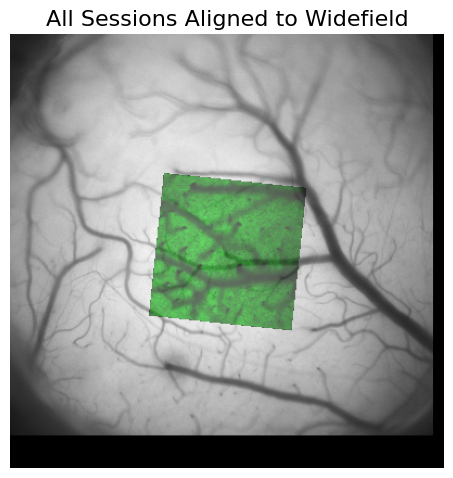

In [141]:
import cv2


# Helper function to apply transformation
def transform_image(img, scale, rotation, dx, dy):
    """Apply scale, rotation, and translation to an image."""
    h, w = img.shape[:2]
    center = (w / 2, h / 2)
    
    M_rot = cv2.getRotationMatrix2D(center, rotation, scale)
    M_rot[0, 2] += dx
    M_rot[1, 2] += dy
    
    transformed = cv2.warpAffine(
        img, M_rot, (w, h),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )
    return transformed

# Get widefield reference
widefield = alignment_params['widefield_maps']['img'].copy()
widefield_norm = (widefield - widefield.min()) / (widefield.max() - widefield.min())

# Create composite
composite = np.stack([widefield_norm, widefield_norm, widefield_norm], axis=2)

mean_image = ops['meanImg']
params = alignment_params['field_coordinates_widefield'][4]
mean_img_norm = (mean_image - mean_image.min()) / (mean_image.max() - mean_image.min())
mean_img_resized = cv2.resize(mean_img_norm,
                            (widefield.shape[1], widefield.shape[0]),
                            interpolation=cv2.INTER_LINEAR)

transformed = transform_image(
    mean_img_resized,
    params['scale'],
    params['rotation'],
    params['dx'],
    params['dy']
)

print(params)

# Blend using alpha compositing in green
alpha = 0.6
session_green = np.zeros_like(composite)
session_green[:, :, 1] = transformed
mask = (transformed > 0).astype(float)
composite = composite * (1 - alpha * mask[:, :, None]) + session_green * alpha

# Create figure
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(composite)
ax.set_title('All Sessions Aligned to Widefield', fontsize=16)
ax.axis('off')
plt.tight_layout()
plt.show()

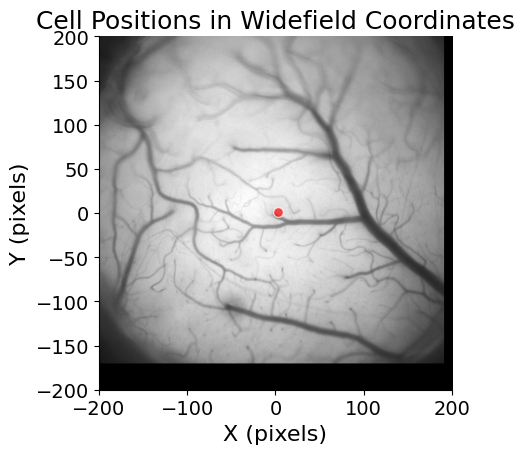

In [30]:
# Combine all the session dataframes into a single dataframe, adding session metadata for each cell
SAM041_dfs = []

for i, (df, (mouse_name, record_date, experiment_name)) in enumerate(zip(session_dfs, session_infos)):
    if df is None:
        continue  # Skip empty sessions
    # If df is a list of DataFrames (e.g., one per condition), concatenate them
    # But usually, it's a pandas DataFrame

    if isinstance(df, list):
        df_all = pd.concat(df, ignore_index=True)
    else:
        df_all = df.copy()

    # Save original cell ids before resetting
    if 'cell_id' in df_all.columns:
        df_all['original_cell_id'] = df_all['cell_id']
    else:
        df_all['original_cell_id'] = np.arange(len(df_all))  # fallback if column not present

    # Set new unique cell_id by resetting index within the session
    df_all = df_all.reset_index(drop=True)
    # Set cell_id to ensure unique within global set: session_num * 10_000 + session_cell_index
    df_all['cell_id'] = (i+1) * 10_000 + df_all.index

    # Add origin columns
    df_all['mouse_name'] = mouse_name
    df_all['record_date'] = record_date
    df_all['experiment_name'] = experiment_name
    # Optional: add session index for reference
    df_all['session_num'] = i+1
    SAM041_dfs.append(df_all)

# Concatenate all cells across sessions into one DataFrame
SAM041_df = pd.concat(SAM041_dfs, ignore_index=True)

# Now all_cells_df contains all cells across sessions, with origin information for each cell


In [31]:
SessionPlots = SingleSessionPlots(SAM041_df)

Reliable cells: 2544 (19.6%)
Not reliable cells: 10406 (80.4%)
Monocular cells: 181 (7.1%)
Binocular cells: 434 (17.1%)
Both cells: 149 (5.9%)
None cells: 1780 (70.0%)


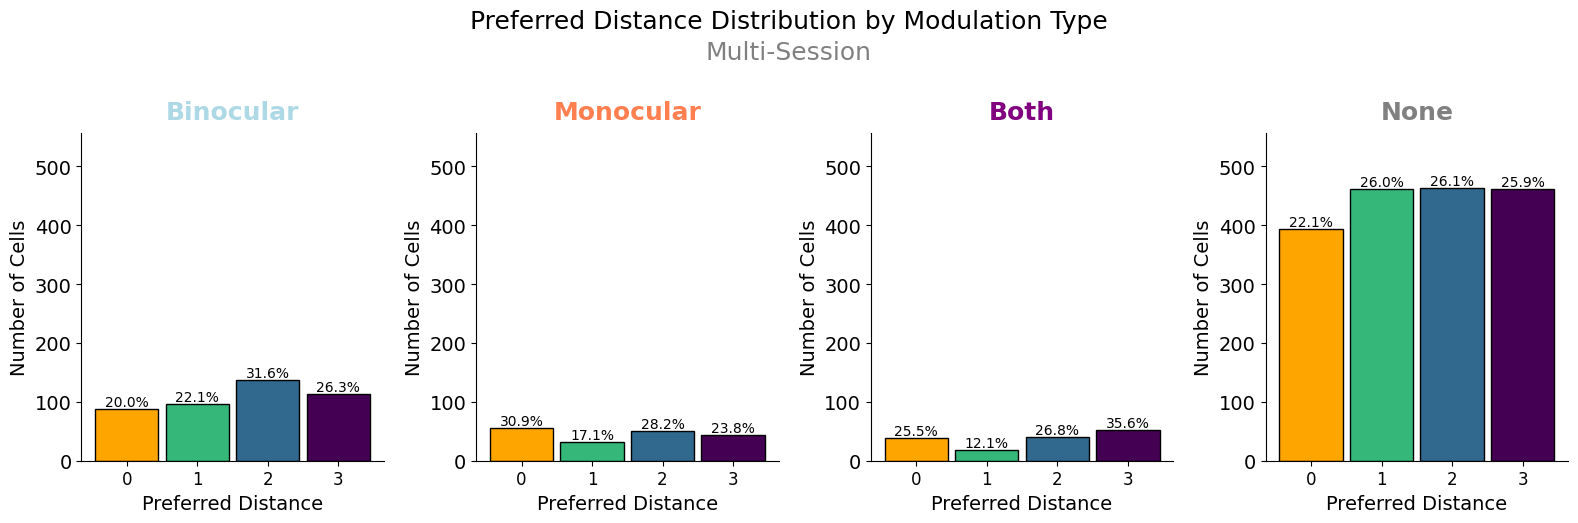

In [25]:
fig, axes = SessionPlots.plot_distance_bars()

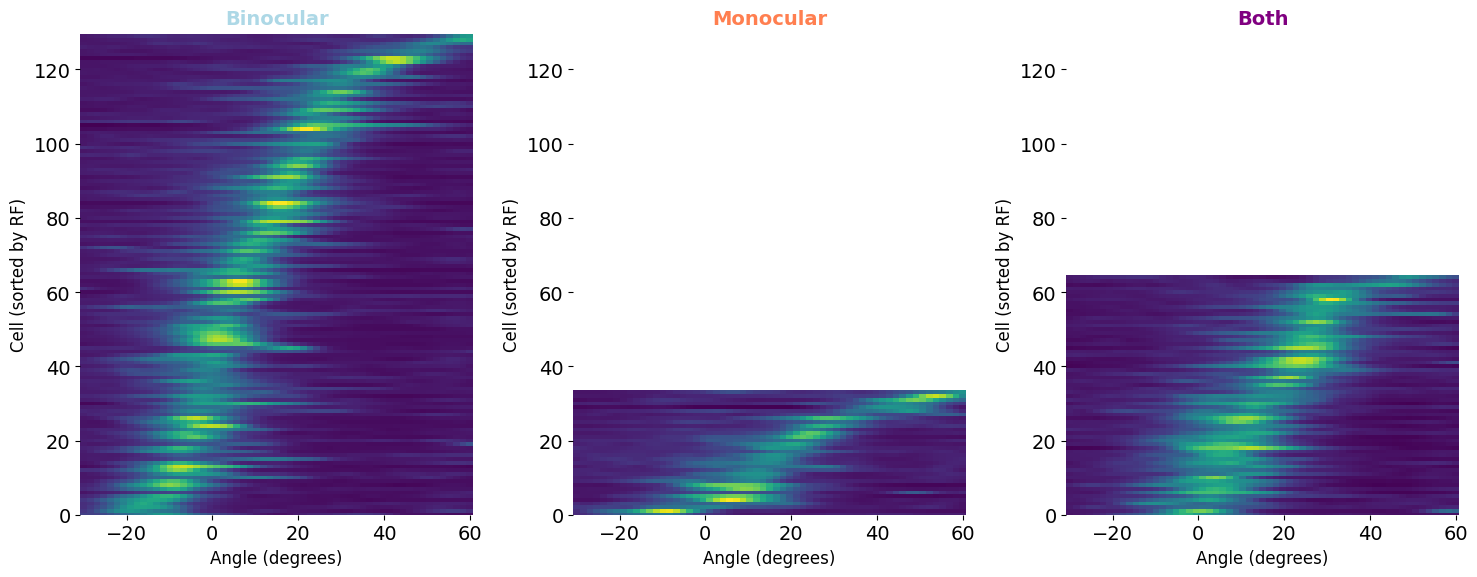

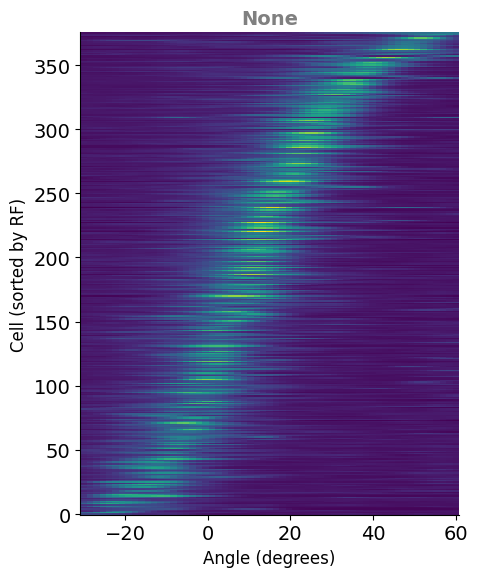

In [11]:
SessionPlots.plot_mean_traces()

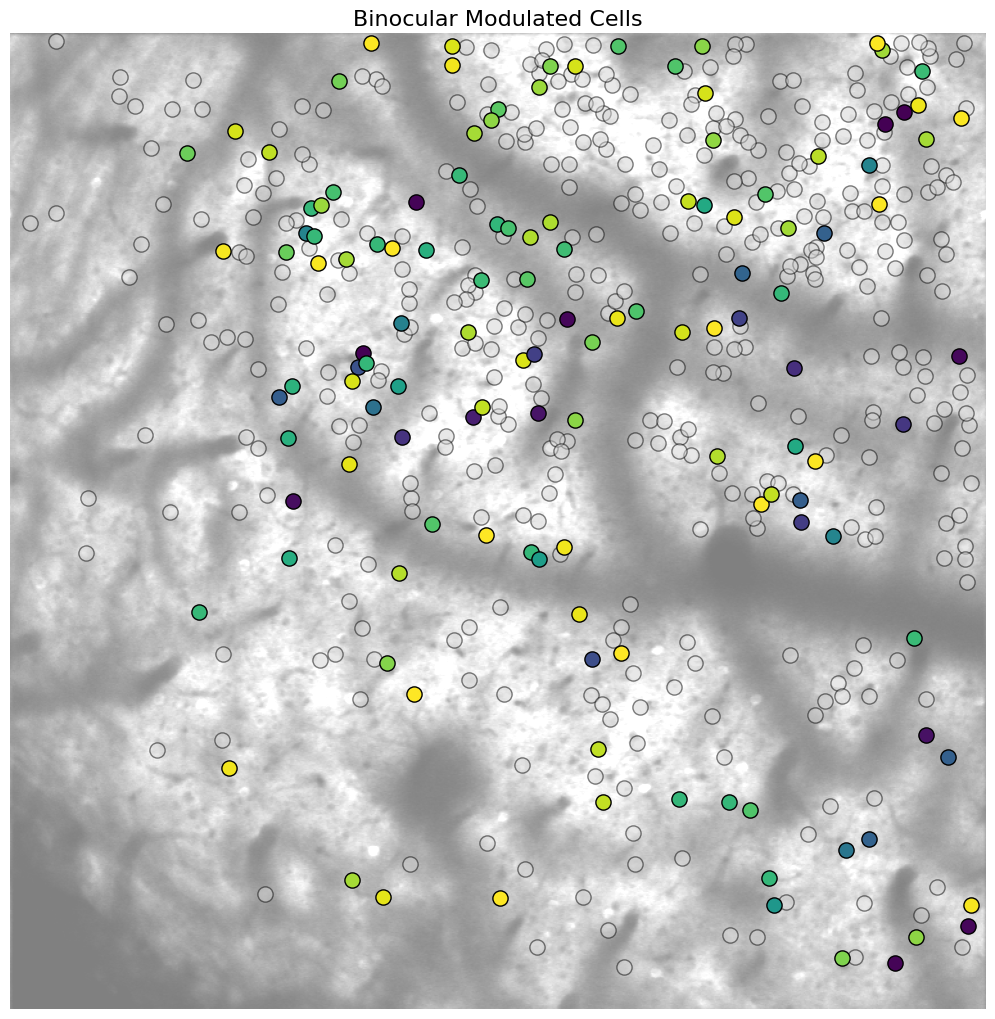

(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Binocular Modulated Cells'}>)

In [12]:
SessionPlots.plot_modulated_cells_map(condition='binocular')

2544


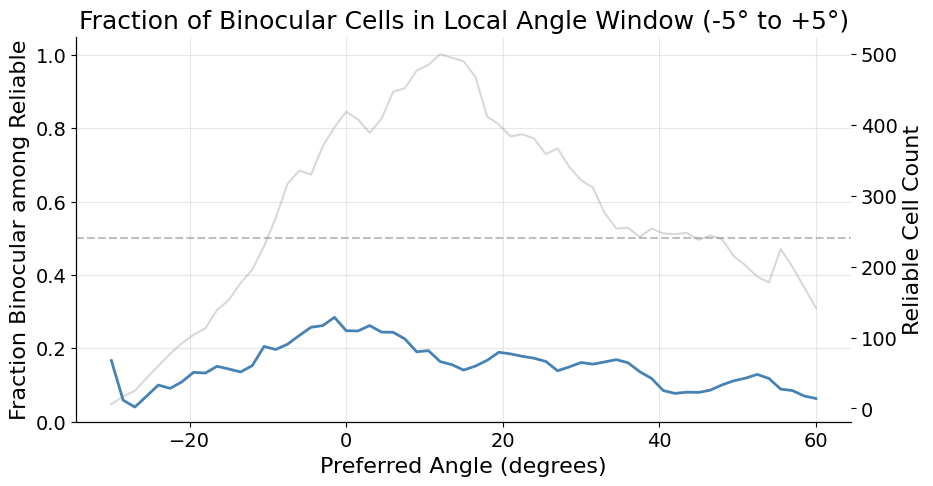

In [35]:
reliable_cells = SessionPlots.reliable_classes['reliable']
print(len(reliable_cells))
reliable_cells_rf = SessionPlots.extract_general_feature(cell=reliable_cells, feature='RF')

condition = 'binocular'
binocular_cells = SessionPlots.modulated_classes[condition]
binocular_cells_rf = SessionPlots.extract_condition_feature(cell=binocular_cells, condition=condition, feature='RF')

# Make a smooth plot: for each angle, show the fraction of binocular cells among reliable cells in a sliding RF window
import numpy as np
import matplotlib.pyplot as plt

# Use 1-degree step
angles = R.angle_range

# For each angle, compute mask of -5 to +5 degrees for reliable and binocular cells
frac_binocular_in_reliable = []
counts_reliable = []
counts_binocular = []

reliable_cells_rf = np.array(reliable_cells_rf)
binocular_cells_rf = np.array(binocular_cells_rf)

for ang in angles:
    rf_window = (reliable_cells_rf >= ang-5) & (reliable_cells_rf < ang+5)
    rel_count = np.sum(rf_window)
    # among reliable cells in the window, how many are also binocular? 
    # Take intersection of reliable cells in window and binocular cell RFs in window
    # But to avoid double-counting, match IDs, so do instead: count of binocular_cell RFs in window
    binoc_count = np.sum((binocular_cells_rf >= ang-5) & (binocular_cells_rf < ang+5))
    
    counts_reliable.append(rel_count)
    counts_binocular.append(binoc_count)
    if rel_count > 0:
        frac = binoc_count / rel_count
    else:
        frac = np.nan
    frac_binocular_in_reliable.append(frac)

plt.figure(figsize=(10,5))
plt.plot(angles, frac_binocular_in_reliable, color='steelblue', lw=2)
plt.xlabel('Preferred Angle (degrees)')
plt.ylabel('Fraction Binocular among Reliable')
plt.title('Fraction of Binocular Cells in Local Angle Window (-5° to +5°)')
plt.ylim(0, 1.05)
plt.axhline(0.5, color='gray', ls='--', alpha=0.5)
plt.grid(alpha=0.3)

# Optionally, overlay histogram in background to show reliable cell density
plt.twinx()
plt.plot(angles, counts_reliable, color='gray', alpha=0.3, label='Reliable cell count')
plt.ylabel('Reliable Cell Count')
plt.show()